# LSTM — predict tomorrow's stock price

1. **Raw data:** one closing price per trading day (5 years). Choose the dataset with `DATASET = "patterns"` or `"realistic"` in Step 1.
2. **Massage the data:** calculate daily price changes, then cut them into 30-day **sequences**.
3. **Train** an LSTM on the first 80% of the days: read 30 days of changes → predict the **next day's** change.
4. **Test** on the last 20%: predicted price = last day's price + predicted change. Compare with the simple guess "tomorrow = today".

In [1]:
import torch
import torch.nn as nn
import math
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

torch.manual_seed(0)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"Using device: {device}")

Using device: mps


## From raw data to sequences

```
RAW DATA       Date        Close           one price per trading day
PRICE CHANGE   change = today's Close − yesterday's Close
SEQUENCES      input: 30 days of changes  →  target: the NEXT day's change
               sequence 0: days 1–30  → predict day 31
               sequence 1: days 2–31  → predict day 32
               ...                      slide forward 1 day each time
SPLIT          first 80% of days → train      last 20% → test
```

DATASET = 'patterns'
        Date       Close
0 2021-01-04  148.309998
1 2021-01-05  150.970001
2 2021-01-06  154.880005
3 2021-01-07  156.889999
4 2021-01-08  160.710007
5 2021-01-11  161.910004
6 2021-01-12  161.339996
7 2021-01-13  159.080002
8 2021-01-14  162.710007
9 2021-01-15  159.929993
... 1260 rows


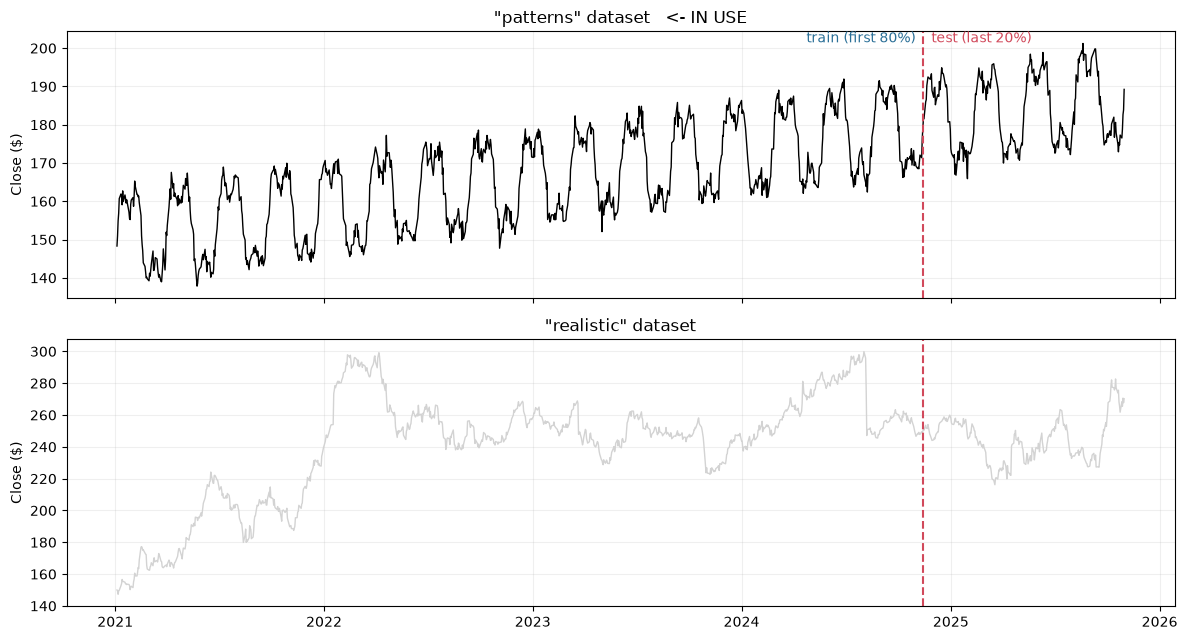

In [2]:
# ---------------------------------------------------------
# Step 1: RAW data — one closing price per trading day
# ---------------------------------------------------------
# With a real stock, this whole cell would just be:
#     raw = pd.read_csv("my_stock.csv")
# We don't have a download, so we simulate 5 years of prices. Pick one:
#   "patterns"  : trend + regular cycles + noise. Fake, but has patterns an LSTM can learn.
#   "realistic" : behaves like a real stock (random % moves, calm and stormy periods,
#                 occasional jumps). Very hard to predict, just like real stocks.
DATASET = "patterns"

YEARS, TRADING_DAYS_PER_YEAR = 5, 252
N_DAYS = YEARS * TRADING_DAYS_PER_YEAR                       # 1,260 trading days
TRAIN_FRACTION = 0.8                                         # first 80% of days -> training
dates = pd.bdate_range("2021-01-04", periods=N_DAYS)         # weekdays only

# --- "patterns" dataset ---
t = torch.arange(N_DAYS).float()
patterns_close = (150 + 0.03 * t                             # slow upward trend
                  + 12 * torch.sin(2 * math.pi * t / 63)     # ~3-month cycle
                  + 5 * torch.sin(2 * math.pi * t / 21)      # ~1-month cycle
                  + 1.5 * torch.randn(N_DAYS))               # random daily noise

# --- "realistic" dataset ---
# Each day the price moves by a random PERCENT. The size of the moves changes over time:
# big moves tend to follow big moves (calm and stormy periods). About twice a year
# there is a jump (like an earnings surprise). Small upward drift on average.
daily_return = torch.zeros(N_DAYS)
variance = 0.012 ** 2                                        # starting daily volatility: 1.2%
for d in range(1, N_DAYS):
    variance = 0.000003 + 0.08 * daily_return[d - 1] ** 2 + 0.90 * variance
    daily_return[d] = 0.0004 + variance ** 0.5 * torch.randn(1)
jumps = (torch.rand(N_DAYS) < 0.008) * torch.randn(N_DAYS) * 0.06
daily_return = daily_return + jumps
realistic_close = 150 * torch.exp(daily_return.cumsum(dim=0))

close = patterns_close if DATASET == "patterns" else realistic_close
raw = pd.DataFrame({"Date": dates, "Close": close.numpy().round(2)})
print(f"DATASET = {DATASET!r}")
print(raw.head(10))
print(f"... {len(raw)} rows")

# Plot both datasets; the chosen one is highlighted
SPLIT_DAY = int(TRAIN_FRACTION * N_DAYS)                     # day 1008
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, name, series in [(axes[0], "patterns", patterns_close), (axes[1], "realistic", realistic_close)]:
    chosen = (name == DATASET)
    ax.plot(dates, series, color="black" if chosen else "lightgray", lw=1)
    ax.axvline(dates[SPLIT_DAY], color="#d1495b", ls="--")
    ax.set(ylabel="Close ($)", title=f'"{name}" dataset' + ("   <- IN USE" if chosen else ""))
    ax.grid(alpha=0.2)
axes[0].text(dates[SPLIT_DAY], axes[0].get_ylim()[1], "train (first 80%)  ", color="#2a6f97", va="top", ha="right")
axes[0].text(dates[SPLIT_DAY], axes[0].get_ylim()[1], "  test (last 20%)", color="#d1495b", va="top")
plt.tight_layout(); plt.show()

In [3]:
# ---------------------------------------------------------
# Step 2: massage — calculate the daily price change
# ---------------------------------------------------------
# Change on day t = Close on day t - Close on day t-1.
# Day 0 has no "yesterday", so 1,260 prices give 1,259 changes.
price = torch.tensor(raw["Close"].values, dtype=torch.float32)   # (1260,)
daily_change = price[1:] - price[:-1]                             # (1259,)

raw["Change"] = [float("nan")] + daily_change.tolist()            # show it in the table
print(raw.head(10))

        Date       Close    Change
0 2021-01-04  148.309998       NaN
1 2021-01-05  150.970001  2.660004
2 2021-01-06  154.880005  3.910004
3 2021-01-07  156.889999  2.009995
4 2021-01-08  160.710007  3.820007
5 2021-01-11  161.910004  1.199997
6 2021-01-12  161.339996 -0.570007
7 2021-01-13  159.080002 -2.259995
8 2021-01-14  162.710007  3.630005
9 2021-01-15  159.929993 -2.780014


In [4]:
# ---------------------------------------------------------
# Step 3: massage — make SEQUENCES (input) and NEXT-DAY targets
# ---------------------------------------------------------
# Sequence i = the changes on days i+1 ... i+30   (30 days the model reads)
# Target  i = the change on day i+31              (the next day, to predict)
#
# unfold(0, size, step) slides a window. Tiny example, 6 values, size 3, step 1:
#   [a, b, c, d, e, f]  ->  [[a, b, c], [b, c, d], [c, d, e], [d, e, f]]
STEPS = 30                                                   # days per sequence
sequences = daily_change.unfold(0, STEPS, 1)[:-1]            # drop the last one: it has no next day
next_change = daily_change[STEPS:]                           # the change on the day after each sequence
last_price = price[STEPS:-1]                                 # price on the last day of each sequence
next_price = price[STEPS + 1:]                               # the price we want to predict
target_day = torch.arange(len(next_change)) + STEPS + 1      # which day each target is

# Divide by SCALE so the numbers are roughly -1..1, which trains better.
# SCALE = typical size of a daily change, measured on the TRAINING days only
# (different datasets move by different amounts).
# unsqueeze adds the last dimension the LSTM expects: (sequences, days, numbers per day).
SCALE = daily_change[:SPLIT_DAY].std().item()
x = (sequences / SCALE).unsqueeze(2)                         # (1229, 30, 1)
y = (next_change / SCALE).unsqueeze(1)                       # (1229, 1)

# Split by TIME: sequences whose target day is in the first 80% train; the rest test.
train_mask = target_day < SPLIT_DAY
test_mask = target_day >= SPLIT_DAY
train_ds = TensorDataset(x[train_mask], y[train_mask])
test_ds = TensorDataset(x[test_mask], y[test_mask])
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256)

print("sequences:", x.shape, "= (sequences, days, numbers per day)    targets:", y.shape)
print("training sequences:", len(train_ds), "   test sequences:", len(test_ds))

sequences: torch.Size([1229, 30, 1]) = (sequences, days, numbers per day)    targets: torch.Size([1229, 1])
training sequences: 977    test sequences: 252


Sequence 0: input = changes on days 1-30
  changes ($): +2.7 +3.9 +2.0 +3.8 +1.2 -0.6 -2.3 +3.6 -2.8 +1.7 -0.9 -1.2 +0.9 -0.8 -2.4 -1.7 -0.2 +4.0 +1.1 +0.6 -2.3 +2.7 +3.9 -1.4 -2.1 -0.0 -0.6 +0.2 -1.8 -3.3
  price on day 30 (last day):  $156.28
  TARGET: change on day 31 = -5.27  ->  price $151.01


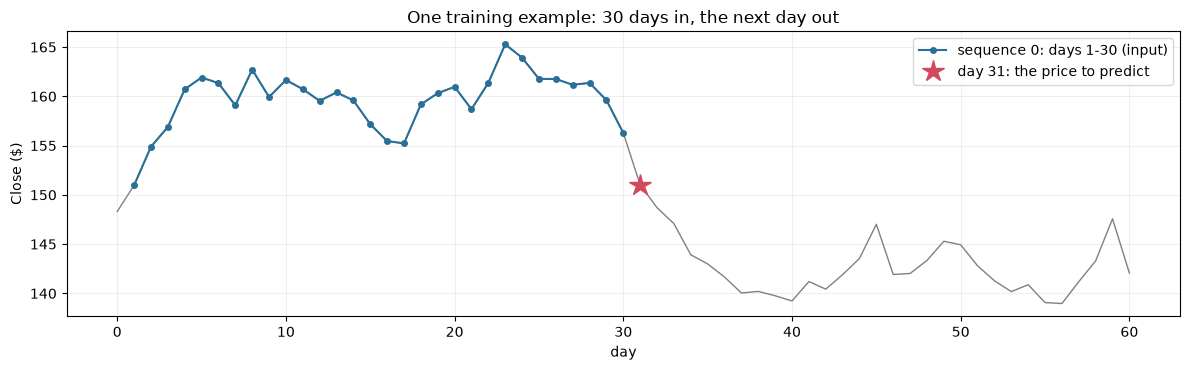

In [5]:
# ---------------------------------------------------------
# Look at one sequence (this cell only prints and plots; it changes nothing)
# ---------------------------------------------------------
n = 0
print(f"Sequence {n}: input = changes on days {n + 1}-{n + STEPS}")
print("  changes ($):", " ".join(f"{v:+.1f}" for v in sequences[n]))
print(f"  price on day {n + STEPS} (last day):  ${last_price[n]:.2f}")
print(f"  TARGET: change on day {n + STEPS + 1} = {next_change[n]:+.2f}  ->  price ${next_price[n]:.2f}")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(range(0, 61), price[:61], color="gray", lw=1)
ax.plot(range(n + 1, n + STEPS + 1), price[n + 1:n + STEPS + 1], "o-", color="#2a6f97", ms=4, label=f"sequence {n}: days {n + 1}-{n + STEPS} (input)")
ax.plot(n + STEPS + 1, next_price[n], "*", color="#d1495b", ms=16, label=f"day {n + STEPS + 1}: the price to predict")
ax.set(xlabel="day", ylabel="Close ($)", title="One training example: 30 days in, the next day out")
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

In [6]:
# ---------------------------------------------------------
# Model: an LSTM layer followed by a Linear layer
# ---------------------------------------------------------
INPUT_SIZE = 1      # numbers per day: price change
HIDDEN_SIZE = 32    # LSTM units
NUM_LAYERS = 1      # stacked LSTM layers
OUTPUT_SIZE = 1     # one prediction: the next day's change

lstm = nn.LSTM(input_size=INPUT_SIZE, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, batch_first=True).to(device)
head = nn.Linear(HIDDEN_SIZE, OUTPUT_SIZE).to(device)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(list(lstm.parameters()) + list(head.parameters()), lr=1e-3)

print(lstm)
print(head)
print("LSTM parameters:  ", sum(p.numel() for p in lstm.parameters()))
print("Linear parameters:", sum(p.numel() for p in head.parameters()))

LSTM(1, 32, batch_first=True)
Linear(in_features=32, out_features=1, bias=True)
LSTM parameters:   4480
Linear parameters: 33


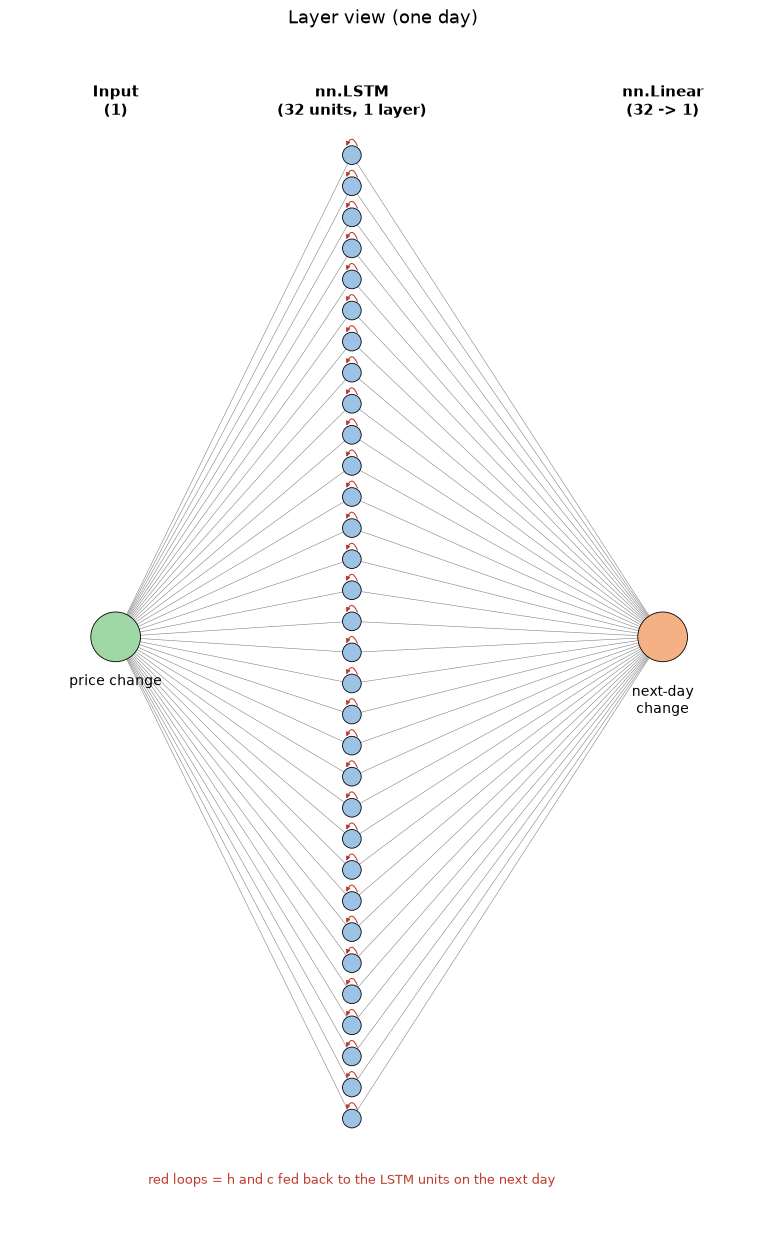

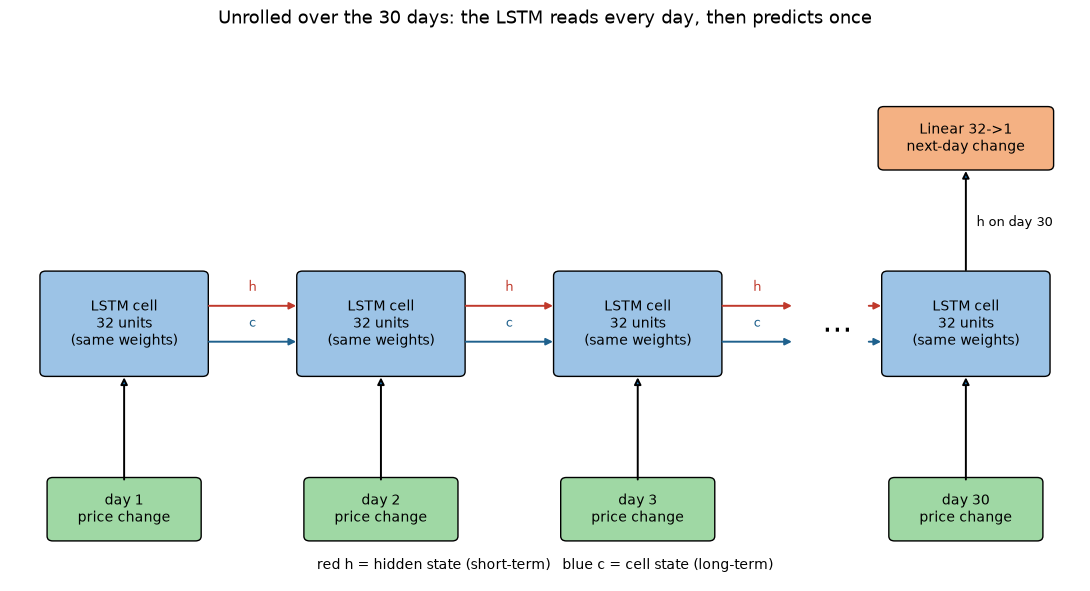

In [7]:
# ---------------------------------------------------------
# Model diagram
# ---------------------------------------------------------
# Layer view (one day): draws every LSTM unit. The column grows with HIDDEN_SIZE.
COL = max(10, 0.5 * HIDDEN_SIZE)           # height of the node column
gap = COL / HIDDEN_SIZE                    # vertical distance between LSTM nodes
r = min(0.4, 0.3 * gap)                    # LSTM node radius, shrinks to fit
x_in, x_h, x_out = 1.2, 5, 10

fig, ax1 = plt.subplots(figsize=(8, 8 * (COL + 3) / 12))
ax1.set_xlim(-0.5, 11.5); ax1.set_ylim(-1.8, COL + 1.2); ax1.set_aspect("equal"); ax1.axis("off")
y_in = [COL * (k + 0.5) / INPUT_SIZE for k in range(INPUT_SIZE)][::-1]
y_h = [COL * (k + 0.5) / HIDDEN_SIZE for k in range(HIDDEN_SIZE)][::-1]
y_out = [COL * (k + 0.5) / OUTPUT_SIZE for k in range(OUTPUT_SIZE)][::-1]
for xpos, ys, rad, color in [(x_in, y_in, 0.4, "#9fd8a4"), (x_h, y_h, r, "#9cc3e6"), (x_out, y_out, 0.4, "#f4b183")]:
    for yy in ys:
        ax1.add_patch(Circle((xpos, yy), rad, fc=color, ec="black", lw=min(1, 4 * r), zorder=3))
for yi in y_in:
    for yh in y_h:
        ax1.plot([x_in, x_h], [yi, yh], c="gray", lw=0.4, zorder=1)
for yh in y_h:
    for yo in y_out:
        ax1.plot([x_h, x_out], [yh, yo], c="gray", lw=0.4, zorder=1)
    # recurrent loop: leaves the top-right of the node, arcs over the top, re-enters at the top-left
    ax1.add_patch(FancyArrowPatch((x_h + 0.7 * r, yh + 0.7 * r), (x_h - 0.7 * r, yh + 0.7 * r),
                                  connectionstyle="arc3,rad=1.4", arrowstyle="-|>",
                                  mutation_scale=max(6, 30 * r), color="#c0392b", lw=min(1.5, 5 * r), zorder=4))
for yi, name in zip(y_in, ["price change"]):
    ax1.text(x_in, yi - 0.6, name, ha="center", va="top", fontsize=10)
ax1.text(x_in, COL + 0.4, f"Input\n({INPUT_SIZE})", ha="center", fontsize=11, weight="bold")
ax1.text(x_h, COL + 0.4, f"nn.LSTM\n({HIDDEN_SIZE} units, {NUM_LAYERS} layer{'s' if NUM_LAYERS > 1 else ''})", ha="center", fontsize=11, weight="bold")
ax1.text(x_out, COL + 0.4, f"nn.Linear\n({HIDDEN_SIZE} -> {OUTPUT_SIZE})", ha="center", fontsize=11, weight="bold")
ax1.text(x_out, y_out[0] - 0.75, "next-day\nchange", ha="center", va="top", fontsize=10)
ax1.text(x_h, -0.8, "red loops = h and c fed back to the LSTM units on the next day", ha="center", fontsize=9, color="#c0392b")
ax1.set_title("Layer view (one day)", fontsize=13, pad=30)
plt.tight_layout(); plt.show()

# Unrolled over days
fig, ax2 = plt.subplots(figsize=(11, 6))
ax2.set_xlim(0, 15); ax2.set_ylim(0, 9); ax2.axis("off")
xs = [1.6, 5.2, 8.8, 13.4]
for xpos, t in zip(xs, ["1", "2", "3", "30"]):
    boxes = [(1.2, 2.0, 0.9, f"day {t}\nprice change", "#9fd8a4"),
             (4.3, 2.2, 1.6, f"LSTM cell\n{HIDDEN_SIZE} units\n(same weights)", "#9cc3e6")]
    if t == "30":                                   # only the LAST day feeds the Linear layer
        boxes.append((7.4, 2.3, 0.9, f"Linear {HIDDEN_SIZE}->{OUTPUT_SIZE}\nnext-day change", "#f4b183"))
    for ypos, w, h, text, color in boxes:
        ax2.add_patch(FancyBboxPatch((xpos - w/2, ypos - h/2), w, h, boxstyle="round,pad=0.08", fc=color, ec="black"))
        ax2.text(xpos, ypos, text, ha="center", va="center", fontsize=10)
    ax2.annotate("", xy=(xpos, 3.45), xytext=(xpos, 1.65), arrowprops=dict(arrowstyle="-|>", lw=1.4))
    if t == "30":
        ax2.annotate("", xy=(xpos, 6.9), xytext=(xpos, 5.15), arrowprops=dict(arrowstyle="-|>", lw=1.4))
        ax2.text(xpos + 0.15, 6.0, "h on day 30", va="center", fontsize=9)
for a, b in zip(xs[:-1], xs[1:]):
    end = 11.0 if b == xs[-1] else b - 1.15
    for ypos, color, label in [(4.6, "#c0392b", "h"), (4.0, "#1f618d", "c")]:
        ax2.annotate("", xy=(end, ypos), xytext=(a + 1.15, ypos), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4))
        ax2.text((a + 1.15 + end) / 2, ypos + 0.25, label, ha="center", fontsize=9, color=color)
for ypos, color in [(4.6, "#c0392b"), (4.0, "#1f618d")]:
    ax2.annotate("", xy=(12.25, ypos), xytext=(12.0, ypos), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4))
ax2.text(11.6, 4.3, "...", fontsize=22, ha="center", va="center")
ax2.set_title("Unrolled over the 30 days: the LSTM reads every day, then predicts once", fontsize=13, y=1.02)
ax2.text(7.5, 0.2, "red h = hidden state (short-term)   blue c = cell state (long-term)", ha="center", fontsize=10)

plt.tight_layout(); plt.show()

In [8]:
# ---------------------------------------------------------
# Train on the first 80%
# ---------------------------------------------------------
EPOCHS = 60
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    lstm.train(); head.train()
    running, count = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        out, _ = lstm(xb)                    # out: (batch, 30 days, HIDDEN_SIZE)
        pred = head(out[:, -1, :])           # use only the LAST day's hidden state -> (batch, 1)
        loss = loss_fn(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)
        count += len(xb)
    history["train"].append(running / count)

    lstm.eval(); head.eval()
    running, count = 0.0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            out, _ = lstm(xb)
            pred = head(out[:, -1, :])
            running += loss_fn(pred, yb).item() * len(xb)
            count += len(xb)
    history["test"].append(running / count)
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:2d}  train {history['train'][-1]:.4f}  test {history['test'][-1]:.4f}")

epoch 10  train 0.6458  test 0.5563


epoch 20  train 0.5970  test 0.5245


epoch 30  train 0.5833  test 0.5172


epoch 40  train 0.5659  test 0.5282


epoch 50  train 0.5558  test 0.5319


epoch 60  train 0.5231  test 0.5042


Typical error (RMSE) on the test days:
  LSTM:                   $1.84
  guess 'tomorrow=today': $2.53


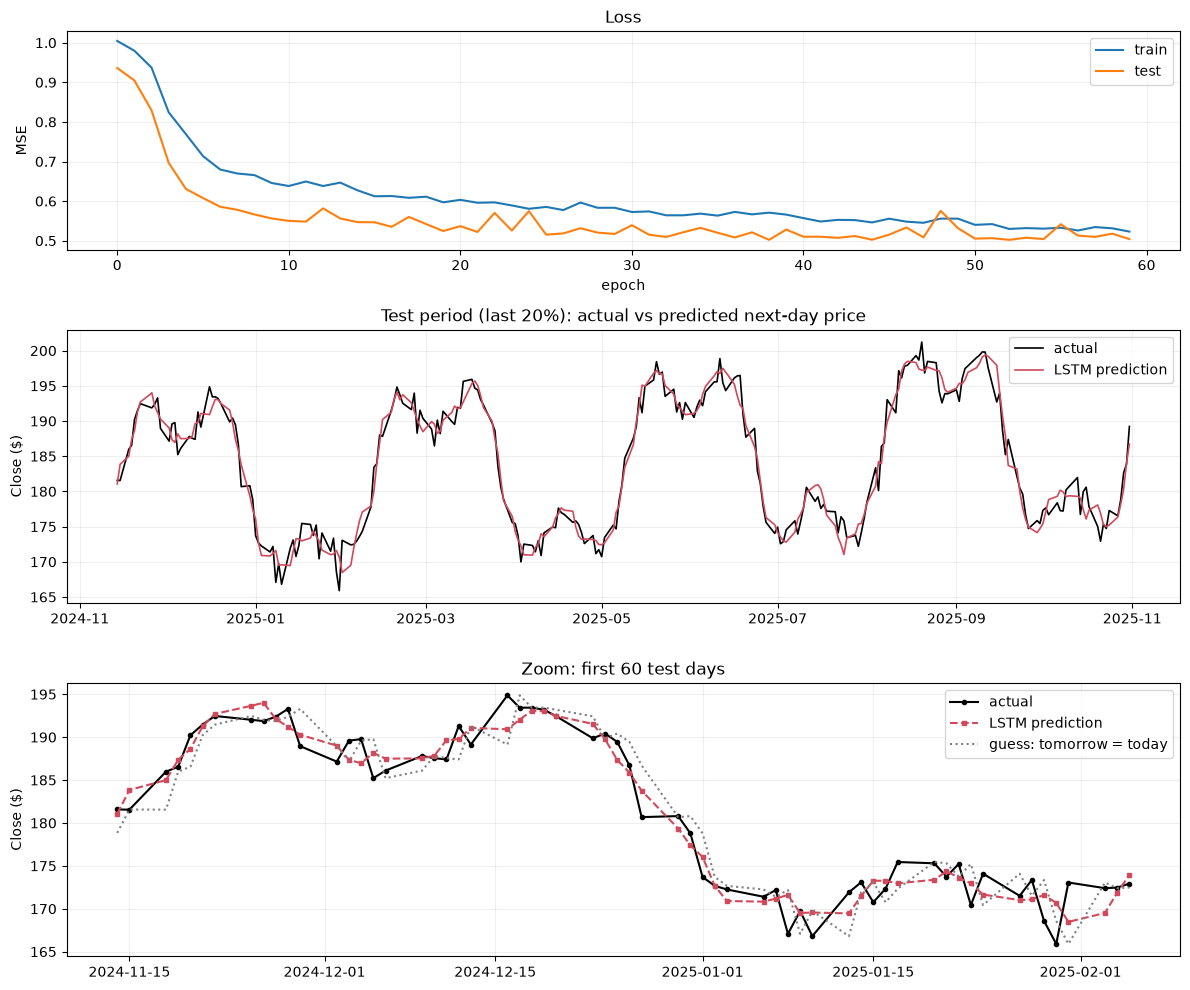

In [9]:
# ---------------------------------------------------------
# Test on the last 20%: predict the next day's price
# ---------------------------------------------------------
lstm.eval(); head.eval()
with torch.no_grad():
    out, _ = lstm(x[test_mask].to(device))
    pred_change = head(out[:, -1, :]).cpu()[:, 0] * SCALE      # back to dollars

pred_price = last_price[test_mask] + pred_change     # LSTM: last price + predicted change
naive_price = last_price[test_mask]                  # simple guess: tomorrow = today
actual_price = next_price[test_mask]
test_dates = raw["Date"].iloc[target_day[test_mask].numpy()]

lstm_error = (pred_price - actual_price).pow(2).mean().sqrt().item()
naive_error = (naive_price - actual_price).pow(2).mean().sqrt().item()
print(f"Typical error (RMSE) on the test days:")
print(f"  LSTM:                   ${lstm_error:.2f}")
print(f"  guess 'tomorrow=today': ${naive_error:.2f}")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), gridspec_kw={"height_ratios": [0.8, 1, 1]})
axes[0].plot(history["train"], label="train"); axes[0].plot(history["test"], label="test")
axes[0].set(xlabel="epoch", ylabel="MSE", title="Loss"); axes[0].legend(); axes[0].grid(alpha=0.2)

axes[1].plot(test_dates, actual_price, color="black", lw=1.2, label="actual")
axes[1].plot(test_dates, pred_price, color="#d1495b", lw=1.2, label="LSTM prediction")
axes[1].set(ylabel="Close ($)", title="Test period (last 20%): actual vs predicted next-day price")
axes[1].legend(); axes[1].grid(alpha=0.2)

ZOOM = 60
axes[2].plot(test_dates[:ZOOM], actual_price[:ZOOM], "o-", color="black", ms=3, label="actual")
axes[2].plot(test_dates[:ZOOM], pred_price[:ZOOM], "s--", color="#d1495b", ms=3, label="LSTM prediction")
axes[2].plot(test_dates[:ZOOM], naive_price[:ZOOM], ":", color="gray", label="guess: tomorrow = today")
axes[2].set(ylabel="Close ($)", title=f"Zoom: first {ZOOM} test days")
axes[2].legend(); axes[2].grid(alpha=0.2)
plt.tight_layout(); plt.show()

 pick | predict day | date       | last price | predicted | actual  | error
------+-------------+------------+------------+-----------+---------+-------


   10 |        1018 | 2024-11-28 |     192.38 |    191.21 |  193.29 | -2.08
   55 |        1063 | 2025-01-30 |     168.59 |    170.68 |  165.90 | +4.78
  115 |        1123 | 2025-04-24 |     175.31 |    173.21 |  174.16 | -0.95
  160 |        1168 | 2025-06-26 |     181.14 |    178.53 |  177.86 | +0.67
  225 |        1233 | 2025-09-25 |     179.62 |    176.03 |  176.68 | -0.65


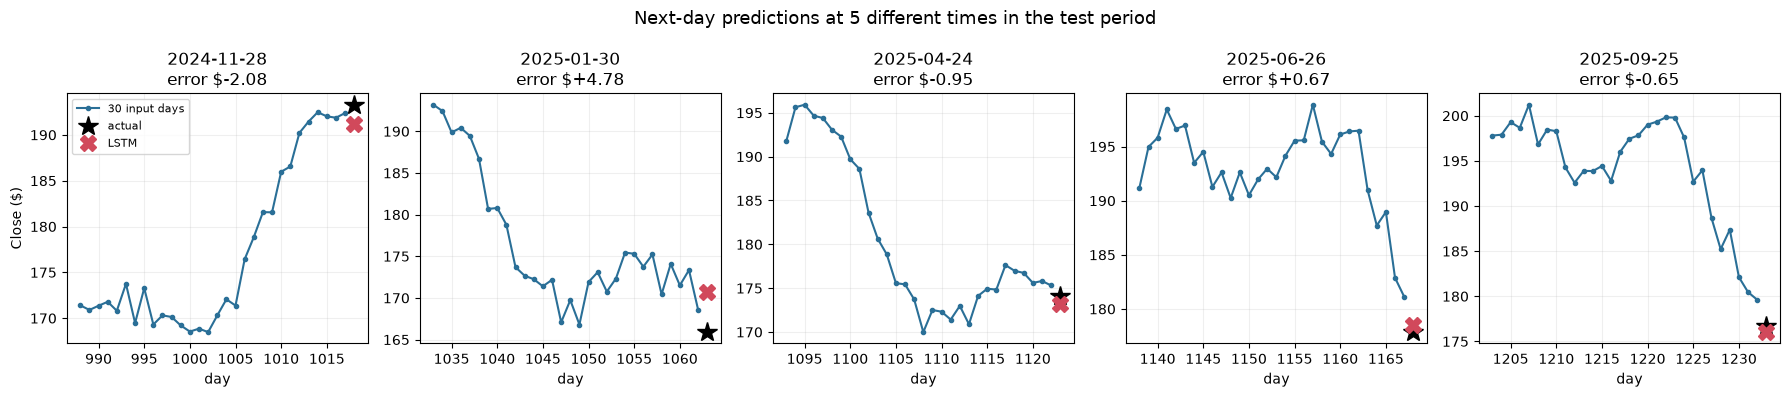

In [10]:
# ---------------------------------------------------------
# 5 example predictions from different times in the test period
# ---------------------------------------------------------
N_TEST = int(test_mask.sum())
PICKS = [10, 55, 115, 160, 225]            # test sequences to show: any numbers from 0 to N_TEST-1

test_index = test_mask.nonzero()[:, 0]                # positions of the test sequences in x
fig, axes = plt.subplots(1, len(PICKS), figsize=(18, 4), sharey=False)
print(" pick | predict day | date       | last price | predicted | actual  | error")
print("------+-------------+------------+------------+-----------+---------+-------")
for ax, pick in zip(axes, PICKS):
    i = test_index[pick].item()                       # index into all sequences
    day = target_day[i].item()                        # the day being predicted
    with torch.no_grad():
        out, _ = lstm(x[i:i + 1].to(device))
        change = head(out[:, -1, :]).item() * SCALE
    predicted = last_price[i].item() + change
    actual = next_price[i].item()
    print(f" {pick:4d} | {day:11d} | {raw['Date'][day].date()} | {last_price[i]:10.2f} | {predicted:9.2f} | {actual:7.2f} | {predicted - actual:+.2f}")

    ax.plot(range(day - STEPS, day), price[day - STEPS:day], "o-", color="#2a6f97", ms=3, label="30 input days")
    ax.plot(day, actual, "*", color="black", ms=15, label="actual")
    ax.plot(day, predicted, "X", color="#d1495b", ms=11, label="LSTM")
    ax.set(xlabel="day", title=f"{raw['Date'][day].date()}\nerror ${predicted - actual:+.2f}")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Close ($)")
axes[0].legend(fontsize=8, loc="best")
fig.suptitle("Next-day predictions at 5 different times in the test period", fontsize=13)
plt.tight_layout(); plt.show()

In [11]:
torch.save({"lstm": lstm.state_dict(), "head": head.state_dict()}, "mylstmmodel.pt")

## Hyperparameters: what to change and what to expect

The dollar amounts below come from real runs on the `"patterns"` data, changing **one** setting at a time.
- The baseline settings in this notebook give a typical next-day error of about **$1.90**. The guess "tomorrow = today" gets $2.53.
- The best possible is about **$1.50**, because the random daily noise can't be predicted.
- Rerunning with a different random seed moves the result by about ±$0.05, so smaller differences are just luck.

| Setting (where) | What to expect |
|---|---|
| **LSTM nodes** `HIDDEN_SIZE` (model cell) | Too few nodes can't hold enough memory. More nodes help a little but cost a lot: 128 nodes = 15× the weights and 2.5× the time. Too many can memorize noise. |
| **FC (Linear) nodes:** add a hidden layer to `head` | No change. The LSTM already did the hard work; a 1-layer head is enough. Example: `head = nn.Sequential(nn.Linear(HIDDEN_SIZE, 16), nn.ReLU(), nn.Linear(16, 1))` |
| **Sequence length** `STEPS` (Step 3) | **One of the biggest effects.** The window must be long enough to see the pattern: this data has 21- and 63-day cycles, and 5 days can't tell where in the cycle you are. Longer windows train slower and give fewer sequences. |
| **LSTM layers** `NUM_LAYERS` | Stacking helps a little here, at 3× the weights and 2× the time. Worth it for complex data. Dropout (`dropout=0.3` in `nn.LSTM`) fights overfitting, but this model isn't overfitting much. |
| **Epochs** `EPOCHS` (train cell) | Too few: still learning. Too many: **overfitting**. At 200, train error falls to $1.53 but test gets worse. Watch the loss plot: stop when the test line flattens. |
| **Learning rate** `lr` (optimizer) | Too small: learns too slowly. Too big: jumpy, and badly overfit (train $1.28, test $2.33). 0.001 is the usual safe start for Adam. |
| **Batch size** `batch_size` (DataLoader) | Little effect on accuracy. Small batches = more updates but **much slower** (8 took 3× as long). |
| **Amount of data** `YEARS` (Step 1) | **The biggest effect.** More history = more examples = better learning. 20 years got closest to the $1.50 floor. |
| **Train/test split** `TRAIN_FRACTION` | More training data usually helps, but leaves fewer test days, so the test score is less reliable. |
| **Dataset** `DATASET` (Step 1) | On `"realistic"` the LSTM only **ties** "tomorrow = today" ($3.13). No setting fixes this: there is no pattern to learn. |

### The main lessons

1. **Data matters most:** more data, and a window long enough to contain the pattern.
2. **Bigger models help only a little,** and cost time. Start small.
3. **Watch train vs. test.** If train keeps improving while test doesn't, you are **overfitting**: use fewer epochs, a smaller model, dropout, or more data.
4. **Always compare against a simple baseline** like "tomorrow = today." Beating it is the real test.
5. **Change one thing at a time,** and rerun with a couple of random seeds before believing a small difference.